# TF variability and positive regulators

chromVAR Z-scores tell you *which* motifs are accessible in *which* cells. Two
follow-up questions from the ArchR workflow are covered here:

1. **Which motifs vary the most across cells?** — `epi.tl.var_deviations`
   (port of ArchR `getVarDeviations`) and `epi.pl.var_dev` (`plotVarDev`).
2. **Which TFs are *positive regulators*, i.e. their motif accessibility rises
   together with the TF's own gene activity?** — `epi.tl.correlate_matrices`
   (port of ArchR `correlateMatrices`) and `epi.tl.positive_tf_regulators`
   (the "Identification of Positive TF-Regulators" recipe of the ArchR book).

Both functions were checked number-for-number against ArchR 1.0.3 on the
ArchR hematopoiesis data; the last section summarises that comparison.

## How the methods work

**Variability.** For every motif ArchR keeps, per sample, the mean and the
unbiased variance of its Z-scores and pools them
(`combinedVars = (Σ (n_s−1)·var_s + n_s·mean_s² − N·mean²) / (N−1)`), which is the
variance over all cells. Motifs are ranked by this value.

**correlateMatrices.** Single cells are too sparse to correlate gene scores with
motif Z-scores directly, so ArchR

1. draws `knn_iteration = 500` seed cells (`set.seed(1); sample()`),
2. takes each seed's `k = 100` nearest neighbours in the (row-z-scored)
   IterativeLSI space,
3. drops groups that share more than `overlap_cutoff·k = 80` cells with an earlier kept group,
4. averages each matrix over the groups, applies `log2(x+1)` to non-negative
   matrices (gene scores; Z-scores are left as is),
5. pairs features by upper-cased name (`GATA1` ↔ `GATA1_383`) and runs a Pearson
   `cor.test` per pair with Bonferroni correction.

Epione reproduces R's random stream bit-exactly — by default the
`L'Ecuyer-CMRG` generator that `addArchRThreads()` switches a multi-threaded
ArchR session to (`rng="archr"`; `rng="R"` for R's default Mersenne-Twister) —
so the seed cells and therefore the groups are *identical* to ArchR's.

**Positive TF regulators.** `maxDelta` = largest difference of cluster-mean
Z-scores between any two clusters. A TF is a positive regulator when
`cor > 0.5`, `padj < 0.01` and `maxDelta` is above its 75th percentile.

## Setup — ArchR hematopoiesis data

We use the ArchR hematopoiesis tutorial data (BMMC, CD34⁺ BMMC and PBMC; Granja *et al.* 2019) processed with
Epione only, as built in the [ArchR hematopoiesis dataset](t_archr_heme_data) tutorial: iterative LSI, Leiden
clusters, gene scores (`epi.tl.add_gene_score_matrix`) and JASPAR2020 chromVAR Z-scores
(`epi.tl.compute_deviations`). Run that tutorial once and point `EPIONE_ARCHR_HEME` at the directory it wrote.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display
import epione as epi

DATA = Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

The gene-score AnnData carries the cells, clusters and the iterative-LSI embedding; the chromVAR Z-scores live in
the peak AnnData. JASPAR motif names are `<matrix ID>_<TF>` (e.g. `MA0035.4_GATA1`); `correlate_matrices` pairs
features by the part of the name before the first `_`, as ArchR does, so we rename motifs to `<TF>_<matrix ID>`
(`GATA1_MA0035.4`). Heterodimer motifs such as `FOS::JUN` then simply find no matching gene.

In [2]:
%%time
adata = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')                  # cells × genes, gene scores
peaks = ad.read_h5ad(DATA / 'heme_peaks.h5ad', backed='r')
z = pd.DataFrame(np.asarray(peaks.obsm['motif_deviations']), index=peaks.obs_names)
adata.obsm['motif_deviations'] = z.loc[adata.obs_names].to_numpy()  # chromVAR Z, cells × motifs

def tf_first(name):
    matrix_id, tf = str(name).split('_', 1)
    return f'{tf.upper()}_{matrix_id}'

adata.uns['motif_deviations_names'] = np.array([tf_first(n) for n in peaks.uns['motif_deviations_names']])
print(adata.uns['motif_deviations_names'][:5])
adata

['ARNT_MA0004.1' 'AHR::ARNT_MA0006.1' 'DDIT3::CEBPA_MA0019.1'
 'MECOM_MA0029.1' 'FOXF2_MA0030.1']
CPU times: user 311 ms, sys: 1.2 s, total: 1.51 s
Wall time: 1.54 s


AnnData object with n_obs × n_vars = 10705 × 20057
    obs: 'Sample', 'n_fragment', 'tsse', 'Clusters'
    var: 'chrom', 'start', 'end', 'strand'
    uns: 'files', 'motif_deviations_names'
    obsm: 'X_iterative_lsi', 'X_umap', 'motif_deviations'

## 1 · Motif variability (`getVarDeviations`)

In [3]:
var = epi.tl.var_deviations(adata, key='motif_deviations', sample_key='Sample')
var.head(10)

   var_deviations: top = GATA1::TAL1_MA0140.2, CEBPA_MA0102.4, GATA2_MA0036.3, CEBPD_MA0836.2, GATA4_MA0482.2


,seqnames,idx,name,combinedVars,combinedMeans,rank
0,z,87,GATA1::TAL1_MA0140.2,10.464485,-0.308779,1
1,z,670,CEBPA_MA0102.4,8.594187,-0.200350,2
2,z,390,GATA2_MA0036.3,8.290045,-0.209587,3
3,z,671,CEBPD_MA0836.2,8.206678,-0.183262,4
4,z,691,GATA4_MA0482.2,7.971213,-0.207140,5
5,z,417,GATA3_MA0037.3,7.556448,-0.178469,6
6,z,433,FOS::JUND_MA1141.1,7.535458,-0.168946,7
7,z,586,SMAD2::SMAD3_MA1622.1,7.418877,-0.165415,8
8,z,60,FOSL2_MA0478.1,7.207937,-0.161642,9
9,z,684,FOSL1_MA0477.2,7.171154,-0.174804,10


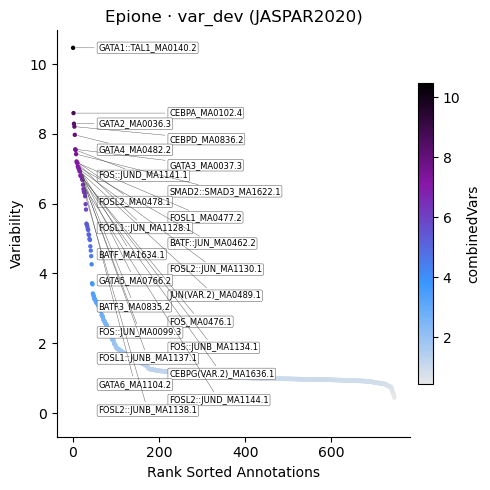

In [4]:
fig, ax = epi.pl.var_dev(adata, n=25, show=False)
ax.set_title('Epione · var_dev (JASPAR2020)')
plt.tight_layout(); plt.show()

The table and plot give the ranking for this dataset. On hematopoietic data the most variable motifs are those of
lineage TF families — GATA (erythroid / megakaryocyte), CEBP and ETS/SPI1 (myeloid), EBF (B cells) — together with
the AP-1 (FOS/JUN) family.

## 2 · Correlating gene scores with motif Z-scores (`correlateMatrices`)

In [5]:
%%time
cor = epi.tl.correlate_matrices(
    adata, key2='motif_deviations',
    name1='GeneScoreMatrix', name2='MotifMatrix',
    use_rep='X_iterative_lsi', scale_dims=True,      # ArchR IterativeLSI default scaleDims=TRUE
    depth_key='n_fragment', cor_cutoff=0.75,         # ArchR getReducedDims(corCutOff = 0.75)
    k=100, knn_iteration=500, overlap_cutoff=0.8, seed=1,
)
print(len(cor.attrs['groups']), 'kNN groups,', len(cor), 'gene–motif pairs')
cor.sort_values('cor', ascending=False).head(10)

   correlate_matrices: testing 685 mappings
   correlate_matrices: 500 non-overlapping kNN groups


500 kNN groups, 685 gene–motif pairs
CPU times: user 767 ms, sys: 167 ms, total: 935 ms
Wall time: 854 ms


,GeneScoreMatrix_name,MotifMatrix_name,cor,padj,pval,GeneScoreMatrix_matchName,MotifMatrix_matchName,GeneScoreMatrix_idx,MotifMatrix_idx
487,LEF1,LEF1_MA0768.1,0.892898,7.277119e-172,1.062353e-174,LEF1,LEF1,14580,227
669,GATA1,GATA1_MA0035.4,0.836168,3.675866e-129,5.366227e-132,GATA1,GATA1,19418,690
503,TCF7,TCF7_MA0769.2,0.812452,6.191921e-116,9.039301e-119,TCF7,TCF7,15307,736
414,CEBPB,CEBPB_MA0466.2,0.788355,2.683964e-104,3.918196e-107,CEBPB,CEBPB,12202,161
309,CEBPA,CEBPA_MA0102.4,0.751198,4.681040e-89,6.833636e-92,CEBPA,CEBPA,9717,670
418,GATA5,GATA5_MA0766.2,0.726320,2.777321e-80,4.054483e-83,GATA5,GATA5,12276,605
199,JDP2,JDP2_MA0655.1,0.722691,4.393488e-79,6.413851e-82,JDP2,JDP2,5935,337
646,NFIL3,NFIL3_MA0025.2,0.713361,4.360935e-76,6.366328e-79,NFIL3,NFIL3,18731,713
511,EBF1,EBF1_MA0154.4,0.706091,7.811270e-74,1.140331e-76,EBF1,EBF1,15571,675
227,ZNF423,ZNF423_MA0116.1,0.698450,1.539960e-71,2.248117e-74,ZNF423,ZNF423,7230,32


As in ArchR, LSI dimensions whose correlation with `log10(nFrags + 1)` exceeds `cor_cutoff = 0.75` are dropped
before the neighbour search (`depth_key` names the per-cell fragment count).

## 3 · Positive TF regulators

In [6]:
%%time
tf = epi.tl.positive_tf_regulators(
    adata, motif_key='motif_deviations', groupby='Clusters',
    use_rep='X_iterative_lsi', scale_dims=True, depth_key='n_fragment', cor_cutoff=0.75,
    k=100, knn_iteration=500, seed=1,
)
tf[tf.TFRegulator == 'YES'][['GeneScoreMatrix_name', 'MotifMatrix_name', 'cor', 'padj', 'maxDelta']]

   correlate_matrices: testing 685 mappings
   correlate_matrices: 500 non-overlapping kNN groups


   positive_tf_regulators: 23 positive regulators: LEF1, GATA1, TCF7, CEBPB, CEBPA, GATA5, JDP2, NFIL3, EBF1, ETS1, CEBPD, GATA2, SPIB, NFE2, SPI1, EOMES, NFKB2, MECOM, ZNF384, TBX21
CPU times: user 760 ms, sys: 109 ms, total: 869 ms
Wall time: 794 ms


,GeneScoreMatrix_name,MotifMatrix_name,cor,padj,maxDelta
0,LEF1,LEF1_MA0768.1,0.892898,7.277119e-172,2.304437
1,GATA1,GATA1_MA0035.4,0.836168,3.675866e-129,3.882023
2,TCF7,TCF7_MA0769.2,0.812452,6.191921e-116,2.447632
4,CEBPB,CEBPB_MA0466.2,0.788355,2.683964e-104,4.433907
5,CEBPA,CEBPA_MA0102.4,0.751198,4.681040e-89,6.037527
8,GATA5,GATA5_MA0766.2,0.726320,2.777321e-80,8.207216
9,JDP2,JDP2_MA0655.1,0.722691,4.393488e-79,4.878925
10,NFIL3,NFIL3_MA0025.2,0.713361,4.360935e-76,3.141952
11,EBF1,EBF1_MA0154.4,0.706091,7.811270e-74,4.752021
14,ETS1,ETS1_MA0098.3,0.690383,3.406951e-69,2.316680


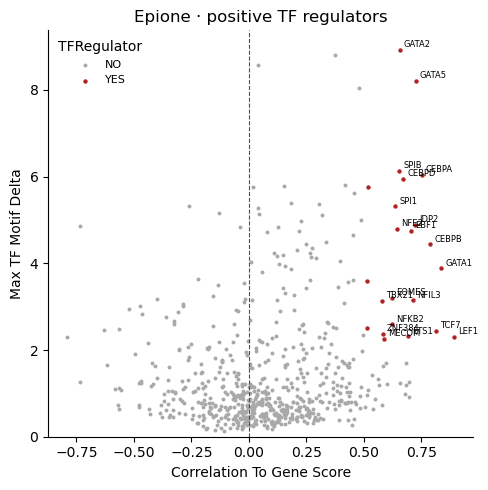

In [7]:
fig, ax = epi.pl.tf_regulators(adata, show=False)
ax.set_title('Epione · positive TF regulators')
plt.tight_layout(); plt.show()

## 4 · Parity vs ArchR 1.0.3

All three functions were compared with ArchR 1.0.3 (R 4.4.3) on the ArchR project of this dataset (10,660 cells,
3 samples), feeding both tools identical inputs: the IterativeLSI matrix, the GeneScoreMatrix, and the JASPAR2020
and cisbp chromVAR Z-scores exported from the same Arrow files. Gates were registered in
`tests/parity/var_dev_correlate/MANIFEST.md` before the first comparison and never loosened.

| Output | Class | Gate | Value |
|---|---|---|---|
| `combinedVars` (JASPAR2020 / cisbp) | 1 | ≤ 1e-8 | 2.8e-14 / 4.3e-14 |
| `combinedMeans` (JASPAR2020 / cisbp) | 1 | ≤ 1e-8 | 6.4e-16 / 7.1e-16 |
| variability rank | 1 | 0 mismatches | 0 |
| seed cells (`set.seed(1); sample()`) / kNN groups after overlap filter | 1 | exact | 0 of 500 / identical (492 groups) |
| `cor`, 825 gene–motif pairs | 1 | ≤ 1e-8 | 8.3e-16 |
| −log10 pval / −log10 padj | 1 bounded | ≤ 1e-6 | 3.8e-13 / 3.4e-13 |
| cluster means / `maxDelta` | 1 | ≤ 1e-8 | 1.8e-14 / 4.4e-14 |
| positive TF regulator set (39 TFs) | 7 | identical | identical, same row order |
| `rng="numpy"`: Spearman on `cor` / on −log10 padj | 8 | ≥ 0.90 | 0.989 / 0.954 |
| `rng="numpy"`: regulator-set Jaccard | 5 | ≥ 0.80 | 0.884 |

With the default `rng="archr"` Epione reproduces R's random stream bit-exactly, so it tests the same kNN groups as
ArchR; `rng="numpy"` is the only mode that is not 1:1, by design. The correlation and TF-regulator rows used the
cisbp motif set of the ArchR tutorial, whose names carry gene symbols.

The ArchR reference outputs are generated outside this repository. With them available, the comparison is rerun by
`tests/parity/var_dev_correlate/py_parity.py` and `tests/test_tf_regulators.py`, which read
`$EPIONE_ARCHR_PARITY_DIR/var_dev_correlate/` and are skipped otherwise.

### Notes
* `rng="archr"` (default) emulates `set.seed()` / `sample()` of a
  multi-threaded ArchR session bit-exactly, so Epione and ArchR test the
  *same* kNN groups. `rng="numpy"` gives a different
  but equally valid set of groups; the correlations then agree at the
  statistical level (Spearman ≥ 0.9) rather than to machine precision.
* The kNN search is exact Euclidean (ArchR uses `nabor::knn`), ties broken by
  cell index.
* Correlations need matching names: motif names map to genes after stripping
  `_…`/`-…` (cisbp `GATA1_383` → `GATA1`); JASPAR names (`MA0035.4_GATA1`) are
  renamed to TF-first form first, as in the setup above.